# EEG Feature Extraction (v1)

**Project:** Analysis of Neuro-Acoustic Features from EEG and Speech Signals for Dosha Characterization

**Scope:** sensor-space EEG feature extraction from the finalised preprocessing outputs.
No rereferencing, no interpolation, no connectivity, no EEG-speech fusion, no Dosha modelling.

This notebook is the human-readable report for `EEG features/scripts/extract_eeg_features.py`.
It loads the saved tables if they exist; on a clean checkout it runs the extraction once.

## 1. Inputs and rules

- Feature input file per recording: `signoff_finalization_v2/eeg_qc_summary_v3.csv` (`feature_input_file`).
- 16 recordings use `*_eeg_ica.fif`; 24 use the cleaned pre-ICA `*_eeg.fif` (16 APPROVED ICA outputs).
- 931 one-second artifact windows from `audit_finalization_v1/eeg/artifact_log_v1.csv` are skipped.
- No file in the repository is modified. All outputs are new files under `EEG features/`.
- The acquisition reference is unknown (QC-01), so no Laplacian/CSD/connectivity features are computed.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path(r"E:\REU_DATA")
OUT = ROOT / "EEG features"
sys.path.insert(0, str(OUT / "scripts"))
import eeg_feature_lib as lib  # noqa: E402

print("library:", lib.__file__)
print("outputs exist:", (OUT / "eeg_features_recording_level.csv").exists())
print("feature families:", len(lib.SPECTRAL_FEATURES), "spectral,",
      len(lib.TEMPORAL_FEATURES), "temporal,", len(lib.NONLINEAR_FEATURES), "nonlinear")

library: E:\REU_DATA\EEG features\scripts\eeg_feature_lib.py
outputs exist: True
feature families: 27 spectral, 11 temporal, 4 nonlinear


### Input verification

The QC summary is the machine-readable source of truth for the per-recording
feature input.  It carries the final ICA sign-off decision (16 APPROVED /
14 REJECTED / 0 open) and the readiness label from the independent audit.

In [2]:
qc = lib.load_qc()
art = lib.load_artifacts()
print("QC rows:", len(qc), "| artifact windows:", len(art))
display(qc.groupby("condition").size().to_frame("recordings"))
display(qc[["participant_id", "condition", "feature_input_file",
            "ica_formal_signoff_decision", "audit_readiness"]].head(8))

QC rows: 40 | artifact windows: 931


,recordings
condition,
calm,10
maths,10
meditation,10
speech,10


,participant_id,condition,feature_input_file,ica_formal_signoff_decision,audit_readiness
0,P01,calm,E:\REU_DATA\EEG processed\eeg\P01\calm\P01_cal...,APPROVED,REVIEW_REQUIRED
1,P01,maths,E:\REU_DATA\EEG processed\eeg\P01\maths\P01_ma...,APPROVED,REVIEW_REQUIRED
2,P01,meditation,E:\REU_DATA\EEG processed\eeg\P01\meditation\P...,REJECTED,REVIEW_REQUIRED
3,P01,speech,E:\REU_DATA\EEG processed\eeg\P01\speech\P01_s...,NOT_APPLICABLE_NO_ICA,REVIEW_REQUIRED
4,P02,calm,E:\REU_DATA\EEG processed\eeg\P02\calm\P02_cal...,REJECTED,REVIEW_REQUIRED
5,P02,maths,E:\REU_DATA\EEG processed\eeg\P02\maths\P02_ma...,APPROVED,REVIEW_REQUIRED
6,P02,meditation,E:\REU_DATA\EEG processed\eeg\P02\meditation\P...,APPROVED,REVIEW_REQUIRED
7,P02,speech,E:\REU_DATA\EEG processed\eeg\P02\speech\P02_s...,NOT_APPLICABLE_NO_ICA,REVIEW_REQUIRED


## 2. Extraction

If the output tables are missing, the next cell runs the full extraction
(about 8 minutes on this machine).  If they exist it loads them.  To rebuild
deliberately, delete `EEG features/*.csv` or run the CLI with `--force`.

In [3]:
if not (OUT / "eeg_features_recording_level.csv").exists():
    print("No outputs found; running full extraction...")
    result = lib.run_extraction(force=False)
    print(result["outputs"])
else:
    print("Existing outputs found; loading. Delete them or use the CLI --force to rebuild.")

Existing outputs found; loading. Delete them or use the CLI --force to rebuild.


In [4]:
ch = pd.read_csv(OUT / "eeg_features_channel_level.csv")
rec = pd.read_csv(OUT / "eeg_features_recording_level.csv")
par = pd.read_csv(OUT / "eeg_features_participant_level.csv")
ep = pd.read_csv(OUT / "eeg_features_epoch_level.csv")
log = pd.read_csv(OUT / "eeg_feature_extraction_log.csv")
qcr = pd.read_csv(OUT / "eeg_feature_extraction_quality_report.csv")

for name, df in [("channel-level", ch), ("recording-level", rec),
                 ("participant-level", par), ("epoch-level", ep),
                 ("extraction log", log), ("QC report", qcr)]:
    print(f"{name:18s} {df.shape[0]:>7d} rows x {df.shape[1]:>3d} cols")

channel-level          960 rows x  62 cols
recording-level         40 rows x 158 cols
participant-level       10 rows x 155 cols
epoch-level         382392 rows x  24 cols
extraction log          40 rows x  18 cols
QC report               25 rows x   5 cols


### Channel-level table

One row per recording x channel (40 x 24 = 960).  M1/M2 are retained here for
transparency but flagged `is_scalp_eeg = False` and excluded from all
recording-level aggregates.  Spectral features use the epoch-averaged Welch
PSD; temporal and nonlinear features are averaged over valid epochs.

In [5]:
key = ["recording_id", "channel", "region", "is_scalp_eeg", "rms_uv",
       "abs_power_theta_uv2", "abs_power_alpha_uv2", "abs_power_beta_uv2",
       "rel_power_alpha", "spectral_entropy", "perm_entropy", "higuchi_fd",
       "dfa_alpha", "alpha_peak_freq_hz"]
display(ch[key].head(10))
display(ch[key].describe().T[["mean", "std", "min", "max"]].round(4))

,recording_id,channel,region,is_scalp_eeg,rms_uv,abs_power_theta_uv2,abs_power_alpha_uv2,abs_power_beta_uv2,rel_power_alpha,spectral_entropy,perm_entropy,higuchi_fd,dfa_alpha,alpha_peak_freq_hz
0,P01_calm,Fp1,frontal,True,6.951247,5.094893,2.885026,6.518142,0.075887,0.751914,0.825742,1.582351,1.148640,11.0
1,P01_calm,Fpz,frontal,True,5.862881,4.056459,2.407590,4.102784,0.086726,0.726211,0.811865,1.505322,1.230858,11.0
2,P01_calm,Fp2,frontal,True,6.385981,4.316993,2.591186,4.983092,0.076963,0.698807,0.814129,1.519438,1.208481,11.0
3,P01_calm,F7,frontal,True,13.329633,19.688611,4.850664,7.554794,0.025875,0.503502,0.809686,1.481858,1.332918,8.0
4,P01_calm,F3,frontal,True,5.179354,4.638928,2.355969,3.620102,0.106905,0.777776,0.793917,1.445586,1.264947,11.0
5,P01_calm,Fz,frontal,True,5.199405,6.509061,2.631577,3.377936,0.118489,0.795022,0.791463,1.416659,1.312938,8.0
6,P01_calm,F4,frontal,True,5.374802,4.410833,2.381405,3.684685,0.099636,0.740262,0.796452,1.450012,1.262696,11.0
7,P01_calm,F8,frontal,True,14.825693,23.966624,6.402320,9.244571,0.028710,0.509806,0.803666,1.447122,1.363766,8.0
8,P01_calm,M1,mastoid,False,6.804431,7.140492,4.417969,9.048667,0.116471,0.844280,0.805163,1.487226,1.183946,11.0
9,P01_calm,T7,temporal,True,6.982051,5.269261,2.596779,11.072029,0.060638,0.882442,0.829383,1.625669,1.019721,8.0


,mean,std,min,max
rms_uv,9.1948,4.3744,3.4540,40.0797
abs_power_theta_uv2,8.5722,11.0570,0.8564,109.3303
abs_power_alpha_uv2,10.9649,18.7739,0.5892,211.1834
abs_power_beta_uv2,12.9193,33.8387,1.3297,639.6509
rel_power_alpha,0.1581,0.1573,0.0103,0.7843
spectral_entropy,0.7193,0.1331,0.2570,0.9919
perm_entropy,0.7957,0.0389,0.6408,0.8520
higuchi_fd,1.4784,0.1456,1.1415,1.8399
dfa_alpha,1.1975,0.1581,0.5355,1.7328
alpha_peak_freq_hz,9.7146,1.2476,8.0000,11.5000


### Recording-level table

One row per participant x condition (40).  Global features are means/SDs across
the 22 scalp channels; regional band powers use the fixed region map; asymmetry
is `log10(right) - log10(left)` for eight homologous pairs.

In [6]:
rkey = ["recording_id", "input_variant", "n_epochs_used", "valid_duration_s",
        "artifact_fraction", "rms_uv_mean", "abs_power_alpha_uv2_mean",
        "alpha_peak_freq_hz_mean", "frontal_alpha_asymmetry"]
display(rec[rkey].to_string(index=False))

'  recording_id input_variant  n_epochs_used  valid_duration_s  artifact_fraction  rms_uv_mean  abs_power_alpha_uv2_mean  alpha_peak_freq_hz_mean  frontal_alpha_asymmetry\n      P01_calm           ica            411             411.0           0.324013     6.535100                  3.151588                 9.977273                 0.062600\n     P01_maths           ica            509             509.0           0.147404     6.705719                  2.863312                 8.840909                -0.017753\nP01_meditation       cleaned            597             597.0           0.000000    11.833103                 87.478819                10.545455                 0.077786\n    P01_speech       cleaned             40              40.0           0.069767     9.036735                  3.662778                 8.204545                 0.120859\n      P02_calm       cleaned            343             343.0           0.422559    12.169756                 11.572899                 9.363636

In [7]:
summary = rec.groupby("condition").agg(
    n=("recording_id", "size"),
    valid_s_mean=("valid_duration_s", "mean"),
    rms_mean=("rms_uv_mean", "mean"),
    alpha_power_mean=("abs_power_alpha_uv2_mean", "mean"),
    alpha_peak_mean=("alpha_peak_freq_hz_mean", "mean"),
    frontal_asym_mean=("frontal_alpha_asymmetry", "mean"),
).round(3)
display(summary)

,n,valid_s_mean,rms_mean,alpha_power_mean,alpha_peak_mean,frontal_asym_mean
condition,,,,,,
calm,10,482.5,9.723,6.358,9.993,0.002
maths,10,487.7,7.497,3.968,9.195,0.019
meditation,10,582.6,8.504,26.916,10.466,0.002
speech,10,40.5,10.405,5.678,9.050,0.053


### Participant-level table

Convenience aggregate: mean across the available conditions.  The
recording-level table remains the primary analysis table because condition
effects are large (especially alpha during meditation).

In [8]:
pkey = ["participant_id", "n_recordings", "conditions_available",
        "rms_uv_mean", "abs_power_alpha_uv2_mean", "alpha_peak_freq_hz_mean",
        "frontal_alpha_asymmetry"]
display(par[pkey].to_string(index=False))

'participant_id  n_recordings         conditions_available  rms_uv_mean  abs_power_alpha_uv2_mean  alpha_peak_freq_hz_mean  frontal_alpha_asymmetry\n           P01             4 calm,maths,meditation,speech     8.527664                 24.289124                 9.392045                 0.060873\n           P02             4 calm,maths,meditation,speech    10.013532                 13.641909                 9.369318                -0.115871\n           P03             4 calm,maths,meditation,speech     8.171249                  4.079731                 9.153409                -0.003345\n           P04             4 calm,maths,meditation,speech    10.470247                 13.909117                 9.585227                 0.094169\n           P05             4 calm,maths,meditation,speech    11.652793                 20.481828                 9.335227                -0.115710\n           P06             4 calm,maths,meditation,speech     7.960608                  5.878717               

## 3. Quality control

Checks Q01-Q21 are expected to pass; Q22-Q25 are documented warnings, not
defects.  The most important warning is the ICA/cleaned input mix: the feature
input differs within participants across conditions.  The cleaned-only
sensitivity check is reported in section 6.

In [9]:
display(qcr[["check_id", "check", "status", "value"]].to_string(index=False))
print(qcr["status"].value_counts().to_dict())

'check_id                                      check status                                                     value\n     Q01                     EEG rows in QC summary   PASS                                                        40\n     Q02                  Feature input files exist   PASS                                                     40/40\n     Q03            All recordings have 24 channels   PASS                                                     40/40\n     Q04 Feature-input policy (16 ICA / 24 cleaned)   PASS                                       16 ICA / 24 cleaned\n     Q05                Artifact windows registered   PASS                                                       931\n     Q06         Minimum valid epochs per recording   PASS                                                        30\n     Q07       No NaN/inf in channel-level features   PASS                                                         0\n     Q08                   Band powers non-negative   P

{'PASS': 21, 'WARN': 4}


In [10]:
display(log[["recording_id", "input_variant", "n_epochs_used",
            "valid_duration_s", "artifact_fraction", "status", "runtime_s"]].to_string(index=False))
print("total extraction time (sum of per-recording runtimes):",
      round(log["runtime_s"].sum(), 1), "s")

'  recording_id input_variant  n_epochs_used  valid_duration_s  artifact_fraction status  runtime_s\n      P01_calm           ica            411             411.0           0.324013     OK  11.614941\n     P01_maths           ica            509             509.0           0.147404     OK   6.212189\nP01_meditation       cleaned            597             597.0           0.000000     OK   8.315794\n    P01_speech       cleaned             40              40.0           0.069767     OK   0.688867\n      P02_calm       cleaned            343             343.0           0.422559     OK   4.408522\n     P02_maths           ica            339             339.0           0.430252     OK   4.478365\nP02_meditation           ica            595             595.0           0.000000     OK   8.339385\n    P02_speech       cleaned             35              35.0           0.146341     OK   0.578096\n      P03_calm           ica            580             580.0           0.023569     OK   7.871603\

total extraction time (sum of per-recording runtimes): 390.0 s


## 4. Figures

The saved figures are descriptive only.  No inferential test is performed and
no feature is selected or tuned on the labels.

fig01_psd_by_condition.png


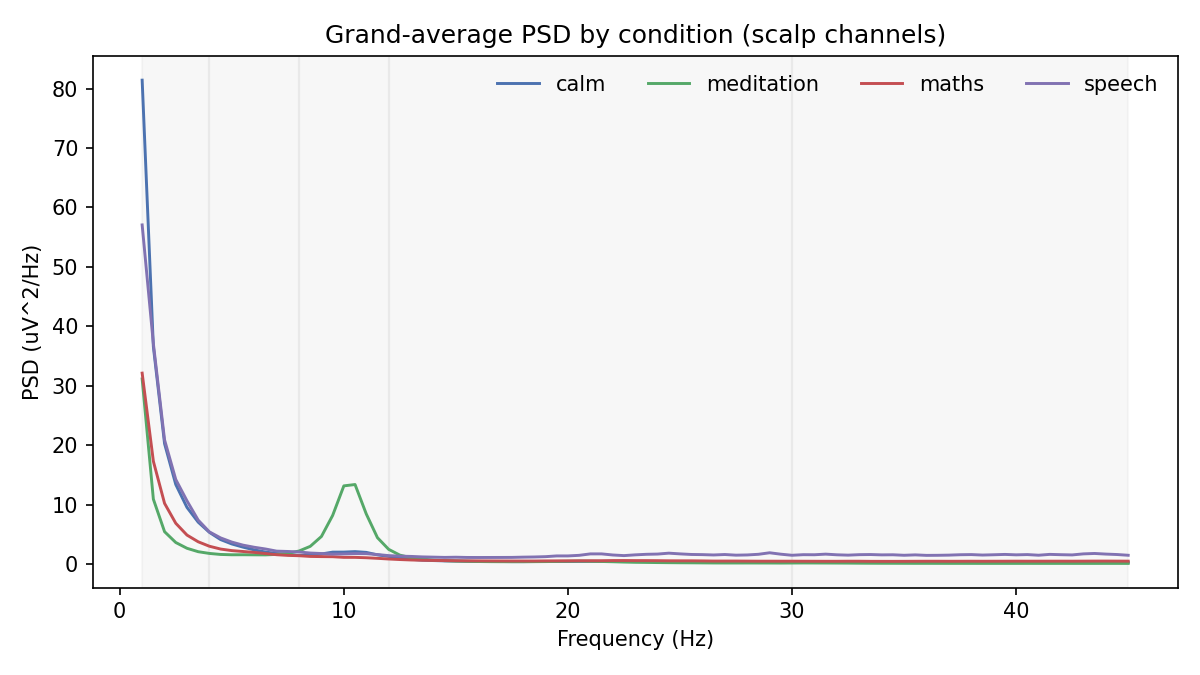

fig02_band_power_by_condition.png


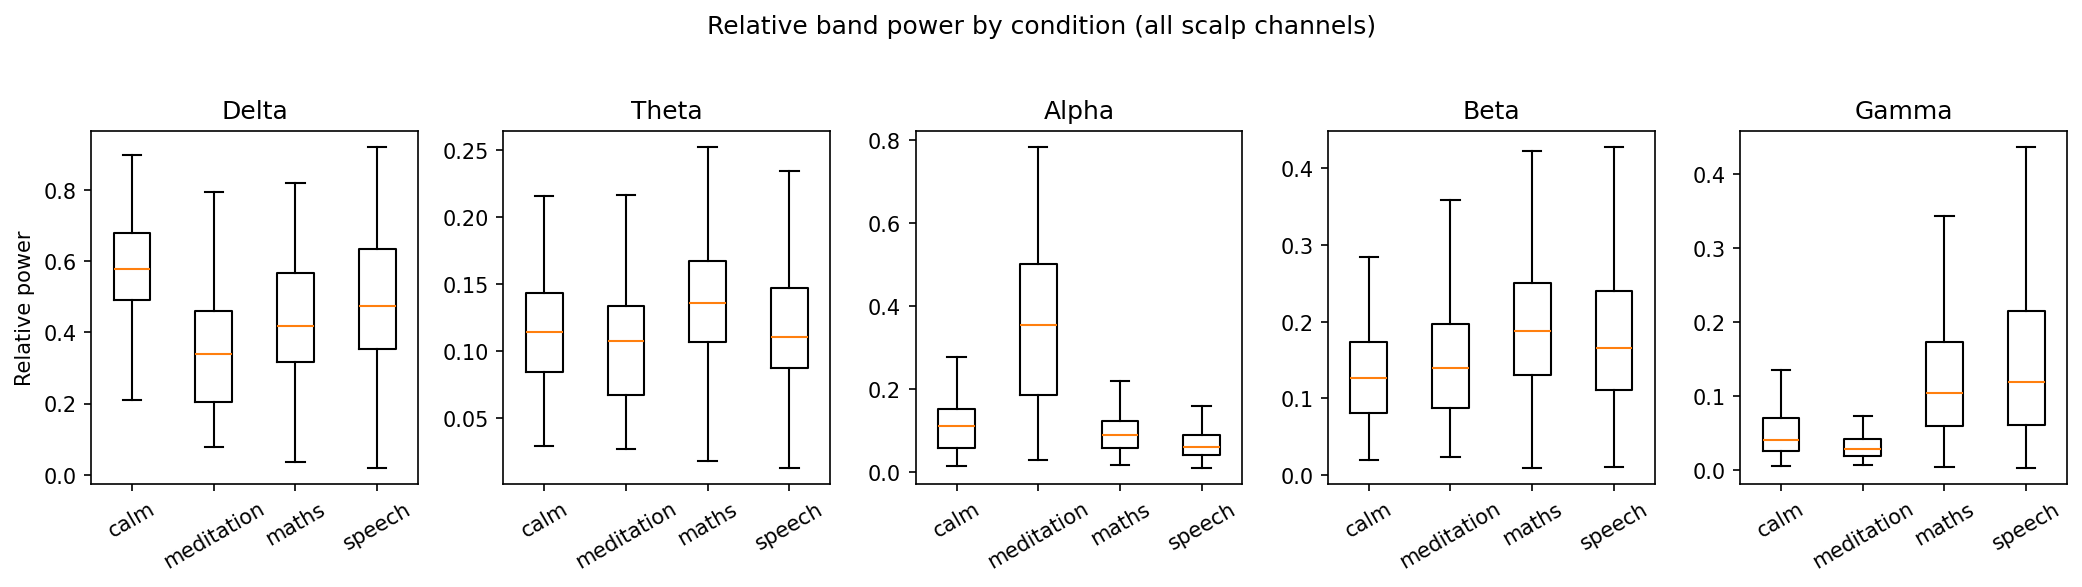

fig03_topography_band_power.png


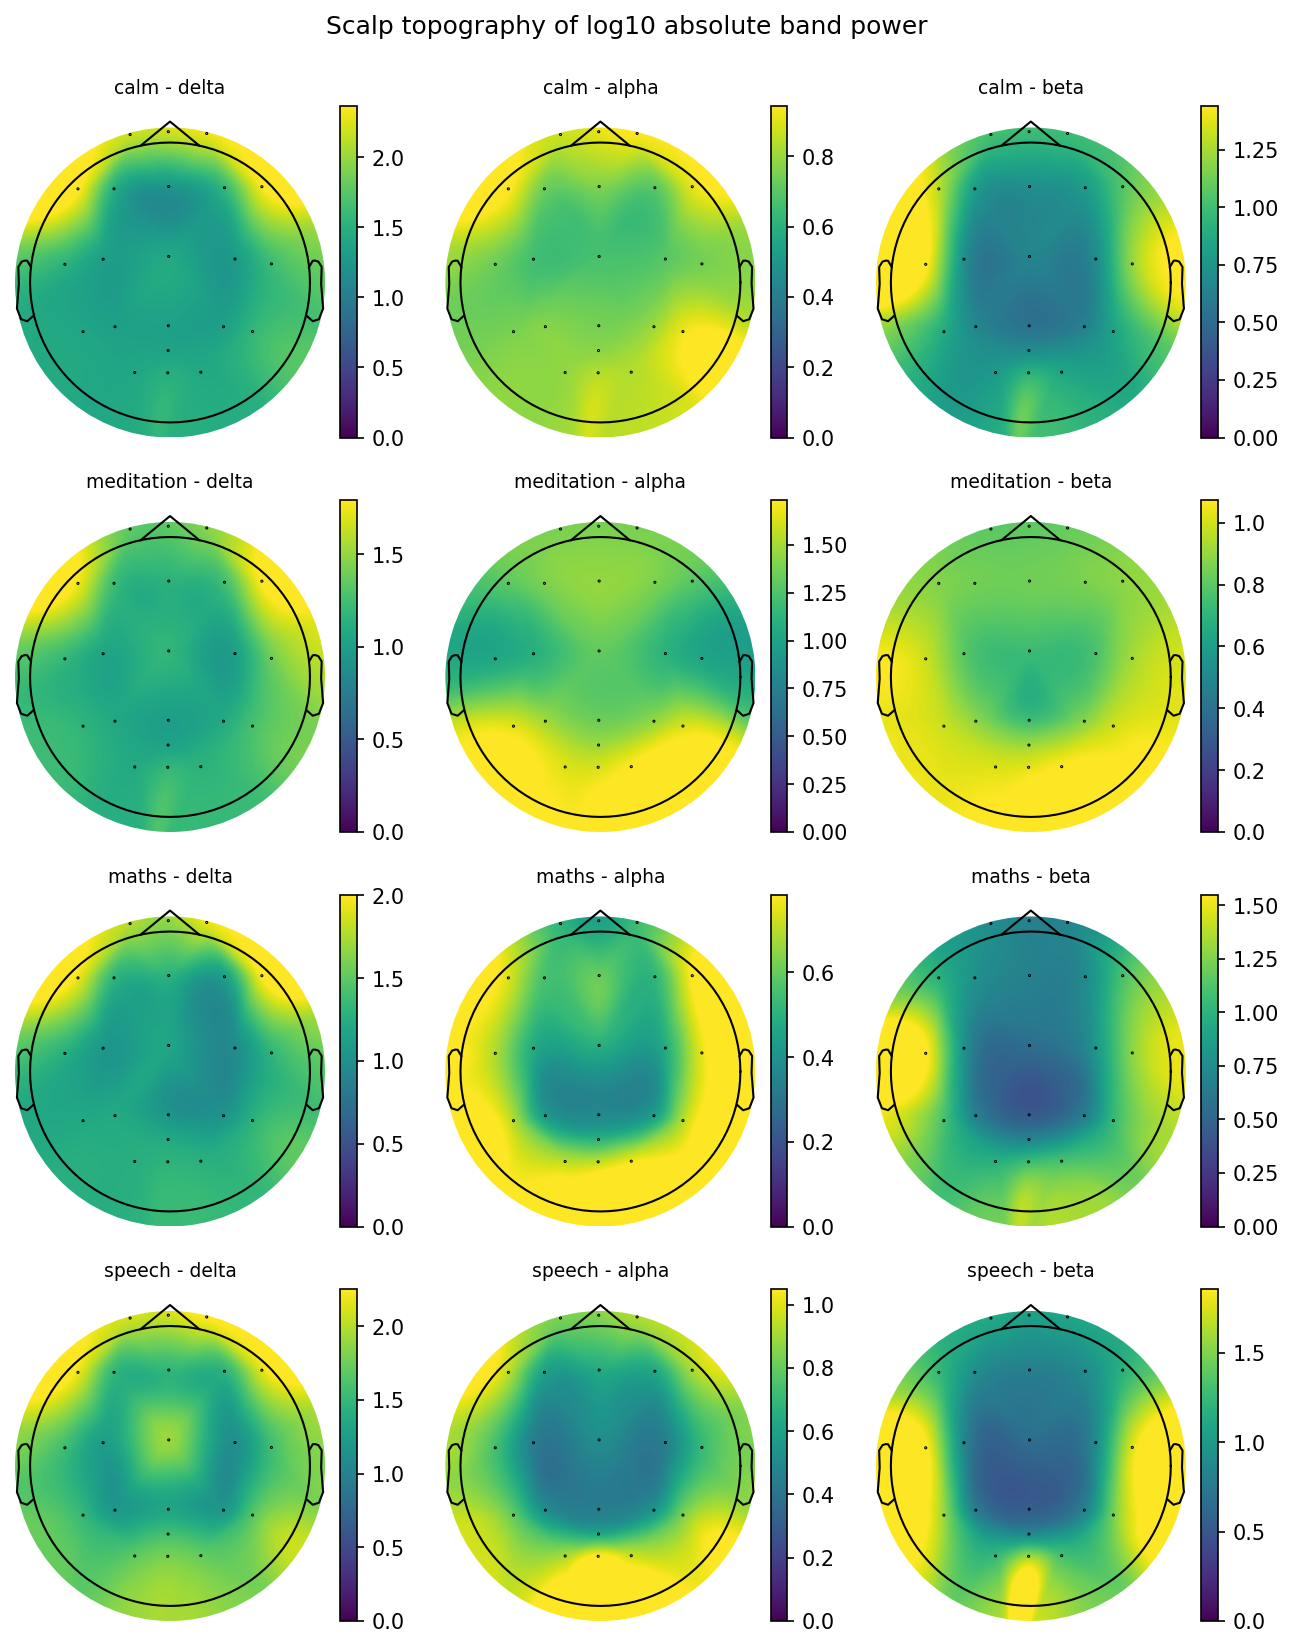

fig04_alpha_peak.png


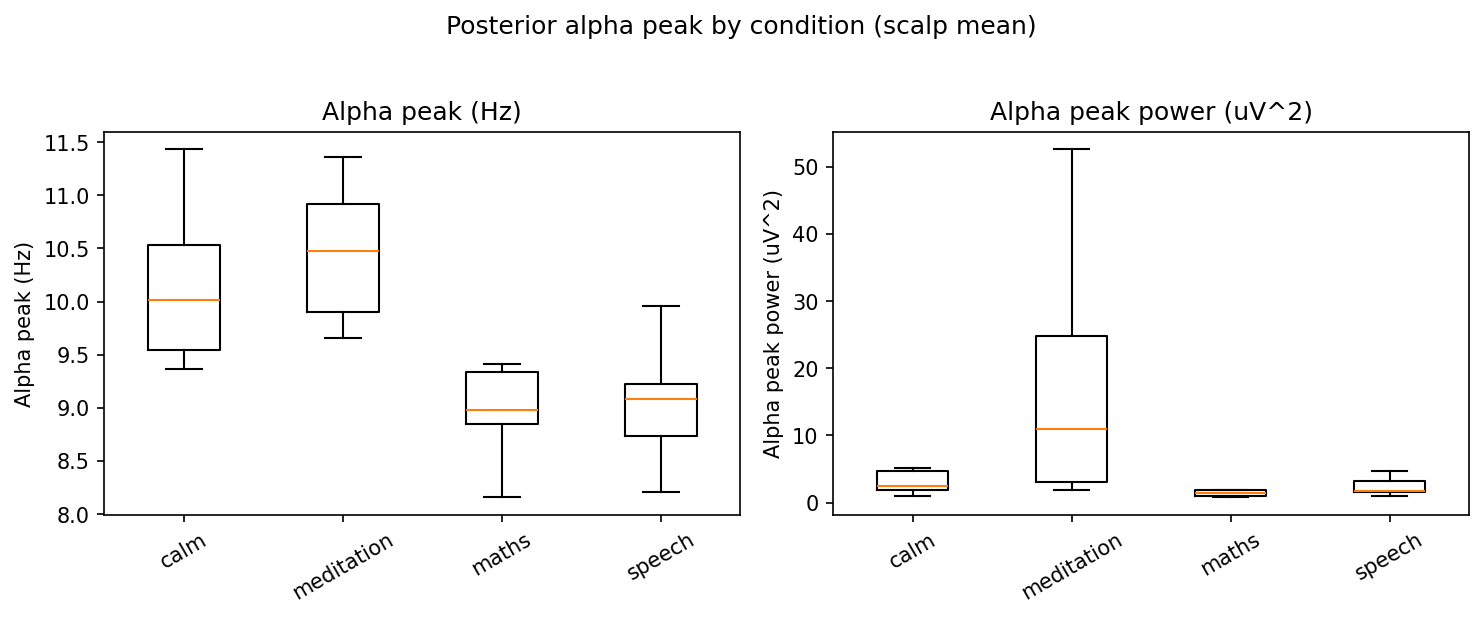

fig05_frontal_alpha_asymmetry.png


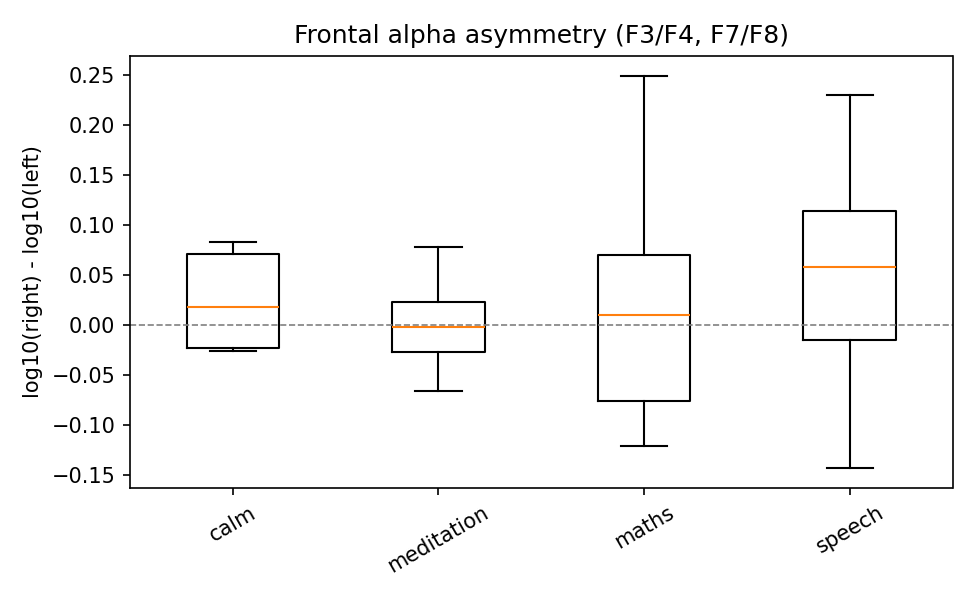

fig06_feature_correlation.png


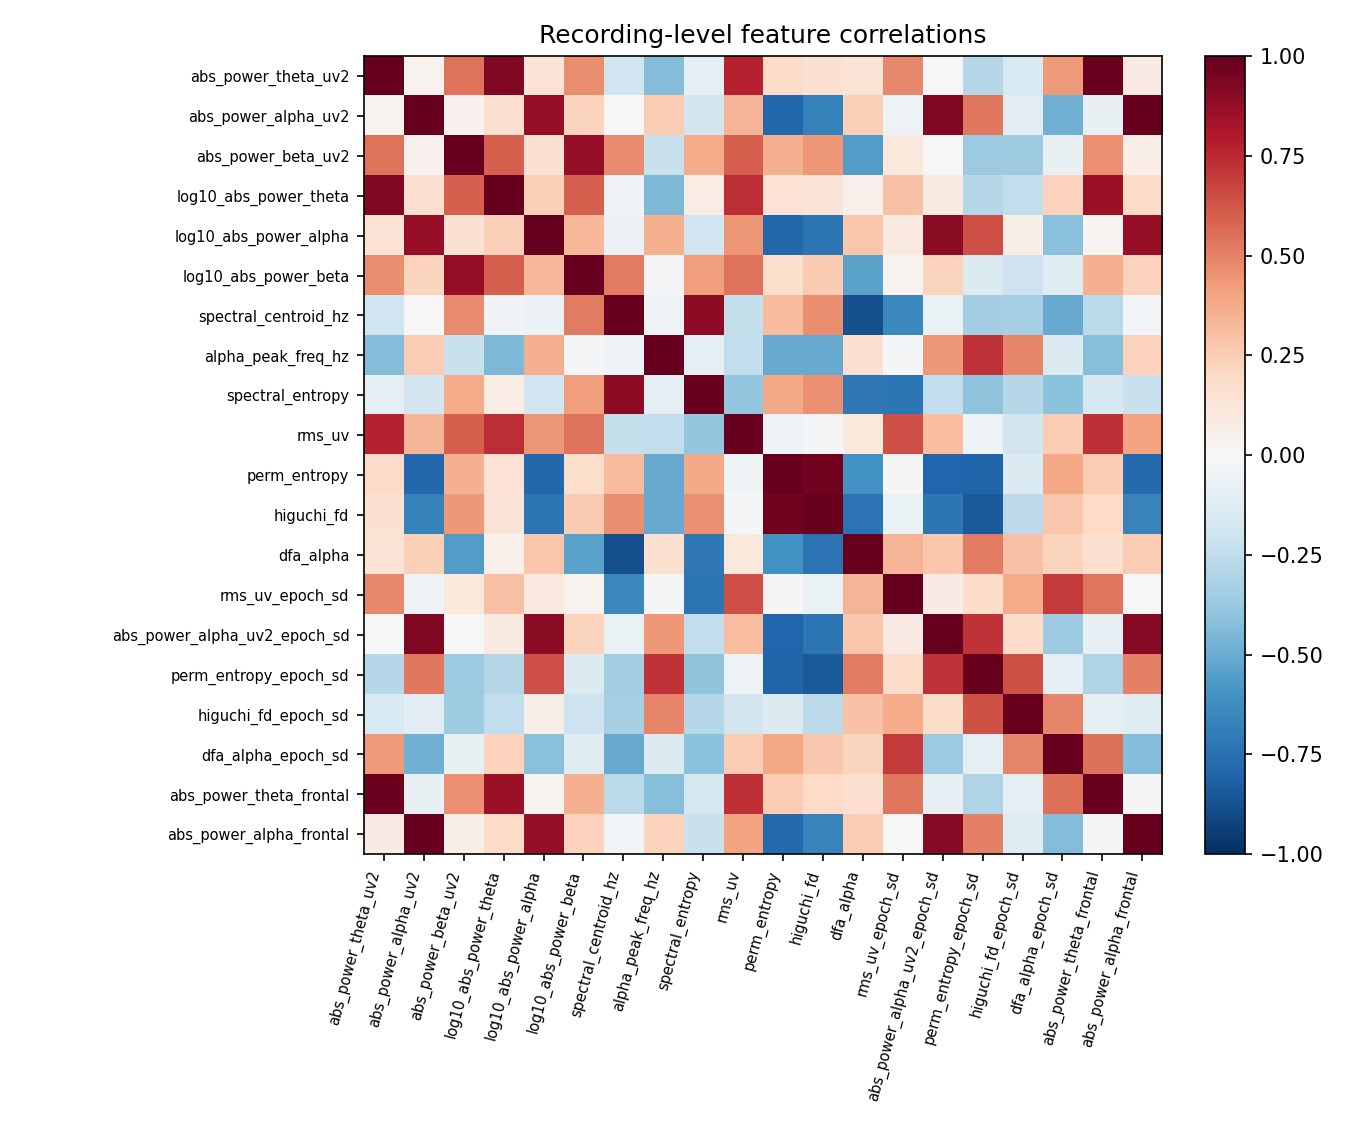

fig07_artifact_impact.png


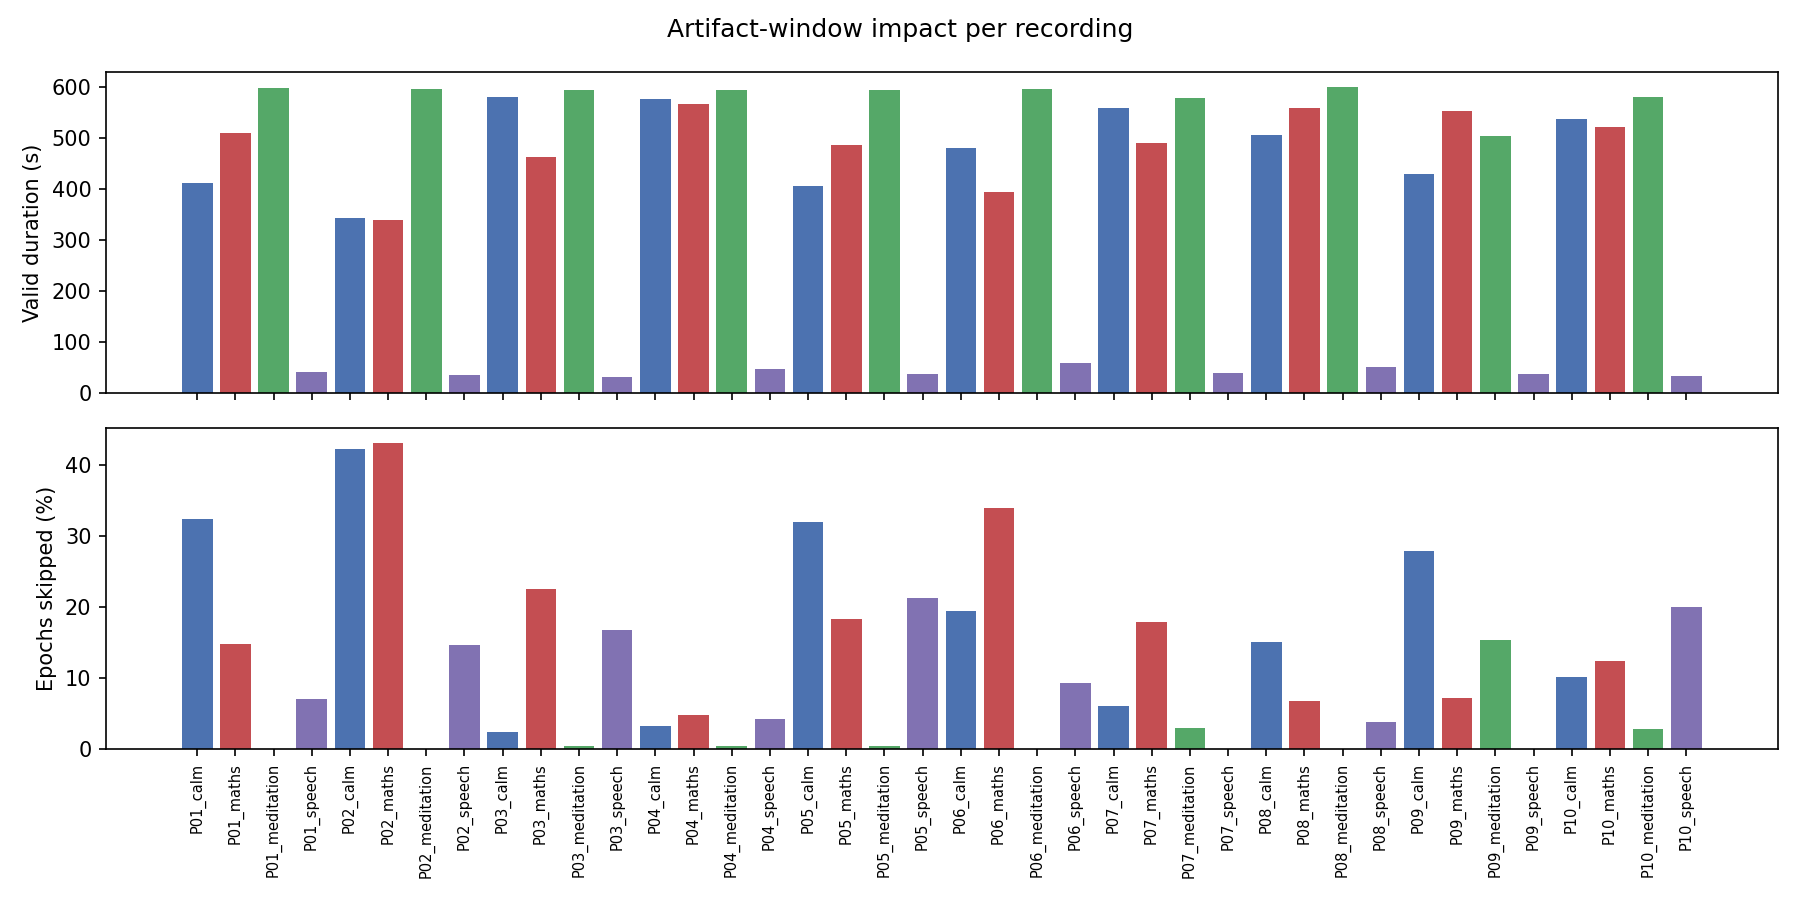

In [11]:
for p in sorted((OUT / "figures").glob("*.png")):
    print(p.name)
    display(Image(filename=str(p)))

## 5. Summary and limitations

The generated summary contains the full methods, output inventory and the
documented limitations.  Read it as part of this notebook, not as a substitute
for it.

In [12]:
display(Markdown((OUT / "eeg_feature_extraction_summary.md").read_text(encoding="utf-8")))

# EEG Feature Extraction - Summary (v1)

**Generated:** 2026-11-02T07:57:02Z
**Notebook:** `notebooks/EEG_Feature_Extraction.ipynb`
**Script:** `EEG features/scripts/extract_eeg_features.py`
**Status:** COMPLETE

## 1. Scope

Sensor-space EEG feature extraction only - no rereferencing, no interpolation, no connectivity,
no EEG-speech fusion, no Dosha modelling. Inputs are the finalised preprocessing outputs
selected by `signoff_finalization_v2/eeg_qc_summary_v3.csv`.

## 2. Inputs (verified, not assumed)

- 40/40 EEG recordings read successfully (16 `*_eeg_ica.fif`, 24 cleaned `*_eeg.fif`).
- 24 channels at 1000 Hz; data already band-passed 1-45 Hz and notched by the preprocessing stage.
- 931 one-second artifact windows skipped (`SKIP_IN_FEATURE_EXTRACTION`), 34 recordings.
- Artifact windows come from the cleaned-file audit; for ICA inputs they are applied conservatively.

## 3. Epochs and features

- 2.0 s epochs, 1.0 s step, linear detrend per epoch; any epoch overlapping an artifact window is skipped.
- Valid epochs per recording: 30-599; valid duration by condition (s):

| condition | min | max | mean |
|---|---:|---:|---:|
| calm | 343.0 | 580.0 | 482.5 |
| maths | 339.0 | 566.0 | 487.7 |
| meditation | 503.0 | 599.0 | 582.6 |
| speech | 30.0 | 59.0 | 40.5 |

- Spectral (per channel, Welch PSD of the epoch-averaged signal): absolute/relative/log band power
  for delta 1-4, theta 4-8, alpha 8-12, beta 12-30, gamma 30-45 Hz; total power; spectral
  centroid; 95% spectral edge; alpha peak frequency/power; theta/alpha, alpha/beta, delta/theta,
  beta/gamma ratios; spectral entropy; simple log-log aperiodic exponent (2-40 Hz, alpha 7-13 Hz
  excluded).
- Temporal (per epoch, averaged): RMS, variance, peak-to-peak, zero-crossing rate, Hjorth
  activity/mobility/complexity, line length, Hilbert envelope mean/SD, lag-1 autocorrelation.
- Nonlinear (per epoch at 250 Hz, averaged): permutation entropy (order 3), Lempel-Ziv
  complexity, Higuchi fractal dimension (kmax 8), DFA exponent (scales 4-64).
- Laterality: log10(right) - log10(left) absolute power for 8 homologous pairs in theta/alpha/beta;
  frontal alpha asymmetry is the mean of F3/F4 and F7/F8.
- M1/M2 are retained in the channel-level table but excluded from all scalp aggregates.

## 4. Outputs

| File | Rows x cols |
|---|---|
| `eeg_features_channel_level.csv` | 960 x 62 |
| `eeg_features_recording_level.csv` | 40 x 158 |
| `eeg_features_participant_level.csv` | 10 x 155 |
| `eeg_features_epoch_level.csv` | 382392 x 24 |
| `eeg_feature_extraction_log.csv` | 40 x 18 |
| `eeg_feature_extraction_quality_report.csv` | 25 x 5 |
| `eeg_psd_by_recording.npz` | 40 recordings x 22 scalp channels x PSD bins |
| `figures/` | 7 PNGs |

## 5. Coverage and QC

- Recordings processed: **40/40**, failures: 0.
- QC checks: {'PASS': 21, 'WARN': 4}.
- No NaN/inf in the channel-level feature table: 0 rows.
- All 40 feature-input paths exist; SHA-256 recorded in the extraction log.

## 6. Limitations

1. n = 10 participants; all results are exploratory. No inferential statistics, classification or
   generalization is claimed.
2. The feature-input policy mixes ICA-cleaned and cleaned files across conditions within participants
   (16 ICA / 24 cleaned). A cleaned-only sensitivity analysis is complete in
   `validation_v1/sensitivity_cleaned_only/`: alpha/beta/Higuchi-FD/alpha-peak are stable,
   while theta/delta/RMS are sensitive to the input choice.
3. The 1 Hz high-pass attenuates low delta; delta 1-4 Hz should be interpreted with that caveat.
4. Gamma 30-45 Hz is a narrow residual band and may contain muscle activity despite artifact
   windowing and ICA.
5. The acquisition reference is unknown (QC-01), so no Laplacian, CSD, average-reference or
   connectivity features were computed.
6. The 110 flagged channel instances were not interpolated (QC-04); they are used as recorded.
7. Speech-condition EEG has only 30-59 s of valid data (37-67 s raw) versus ~10 min for calm/meditation/maths, so condition comparisons must account
   for different effective sample sizes.
8. Dosha labels are provisional and are not merged here. Join on `participant_id` only with an
   explicit provisional-label caveat.
9. The aperiodic exponent is a simple log-log fit excluding 7-13 Hz, not a FOOOF/SPECPARAM
   decomposition.

## 7. Next steps

1. Use the completed cleaned-only sensitivity result (`validation_v1/sensitivity_cleaned_only/`)
   when interpreting theta, delta, RMS or any feature with r < 0.80; alpha/beta/HFD/alpha-peak
   conclusions are stable.
2. Join provisional labels (`Questionnaire_Analysis/participant_labels_v1.csv`) and speech features
   (`analysis_ready/participant_master_v1.csv`) on `participant_id`, keeping the provisional flag.
3. Confirm the acquisition reference before adding reference-sensitive features or connectivity.
4. Decide the interpolation policy for the 110 flagged channels (QC-04).
5. Only after labels are validated: feature selection and modelling with participant-level
   cross-validation; n = 10 is too small for train/test splits that claim generalization.

## 8. Reproduce

```
py -3.14 "EEG features/scripts/extract_eeg_features.py" --force
py -3.14 reports_final_v3/scripts/run_nb.py "notebooks/EEG_Feature_Extraction.ipynb"
```


## 6. Validation and sensitivity

The read-only validation pass is in `validation_v1/`.  It re-hashes every input,
checks the artifact-window rule, recomputes PSD/RMS independently, and runs the
nonlinear kernels on synthetic signals.  The cleaned-only sensitivity pass
recomputes all 40 recordings on `*_eeg.fif` and compares them with the
policy-compliant primary table.

In [13]:
val = pd.read_csv(OUT / "validation_v1" / "validation_results_v1.csv")
display(val[["check_id", "category", "check", "status", "value"]].to_string(index=False))
print(val["status"].value_counts().to_dict())

"check_id    category                                                 check status                                                                                                value\n     V01   structure                                     Output row counts   PASS                                                            channel=960, recording=40, participant=10\n     V02   structure           24 channels per recording; 10 per condition   PASS                   channels=[np.int64(24)]; {'calm': 10, 'maths': 10, 'meditation': 10, 'speech': 10}\n     V03   structure                                     No duplicate keys   PASS                                                                                                    0\n     V04      values                        No NaN/inf in channel features   PASS                                                                                                    0\n     V05      values                         Relative band powers sum to 1   PA

{'PASS': 16, 'WARN': 1}


In [14]:
sens_dir = OUT / "validation_v1" / "sensitivity_cleaned_only"
comp = pd.read_csv(sens_dir / "sensitivity_comparison_v1.csv")
con = pd.read_csv(sens_dir / "sensitivity_condition_contrasts_v1.csv")
key_feats = ["abs_power_alpha_uv2_mean", "abs_power_beta_uv2_mean",
             "abs_power_theta_uv2_mean", "rms_uv_mean", "higuchi_fd_mean",
             "dfa_alpha_mean", "alpha_peak_freq_hz_mean", "frontal_alpha_asymmetry"]
display(comp[comp.feature.isin(key_feats)][
    ["feature", "pearson_r", "spearman_r", "mean_abs_diff", "mean_rel_diff_pct"]
].to_string(index=False))
display(con.to_string(index=False))
print("key sign flips:", int(con["sign_flip"].sum()))

'                 feature  pearson_r  spearman_r  mean_abs_diff  mean_rel_diff_pct\nabs_power_theta_uv2_mean   0.686679    0.602627       2.856872          33.412801\n             rms_uv_mean   0.787548    0.718574       0.941553          10.424600\n          dfa_alpha_mean   0.843776    0.844090       0.030582           2.537376\n alpha_peak_freq_hz_mean   0.943591    0.934591       0.142045           1.467998\n frontal_alpha_asymmetry   0.952319    0.935647       0.015736          17.975416\n         higuchi_fd_mean   0.988101    0.987617       0.011956           0.810900\n abs_power_beta_uv2_mean   0.998081    0.995685       0.259211           2.403285\nabs_power_alpha_uv2_mean   0.999041    0.926079       0.477743           4.452399'

'                 feature               contrast  primary_diff  cleaned_diff  abs_change_pct  sign_flip\nabs_power_alpha_uv2_mean meditation_minus_maths     22.947648     22.367830        2.526698      False\nabs_power_alpha_uv2_mean  meditation_minus_calm     20.558226     20.667171        0.529936      False\nabs_power_theta_uv2_mean meditation_minus_maths     -1.719802     -9.176037      433.552087      False\nabs_power_theta_uv2_mean  meditation_minus_calm     -4.705990     -7.893129       67.725156      False\n abs_power_beta_uv2_mean meditation_minus_maths     -1.094096     -1.676071       53.192240      False\n abs_power_beta_uv2_mean  meditation_minus_calm     -0.725815     -0.794323        9.438722      False\n             rms_uv_mean meditation_minus_maths      1.007074     -0.815271      180.954469       True\n             rms_uv_mean  meditation_minus_calm     -1.218586     -2.330156       91.218030      False\n         higuchi_fd_mean meditation_minus_maths     -0.227232  

key sign flips: 2


fig01_key_feature_agreement.png


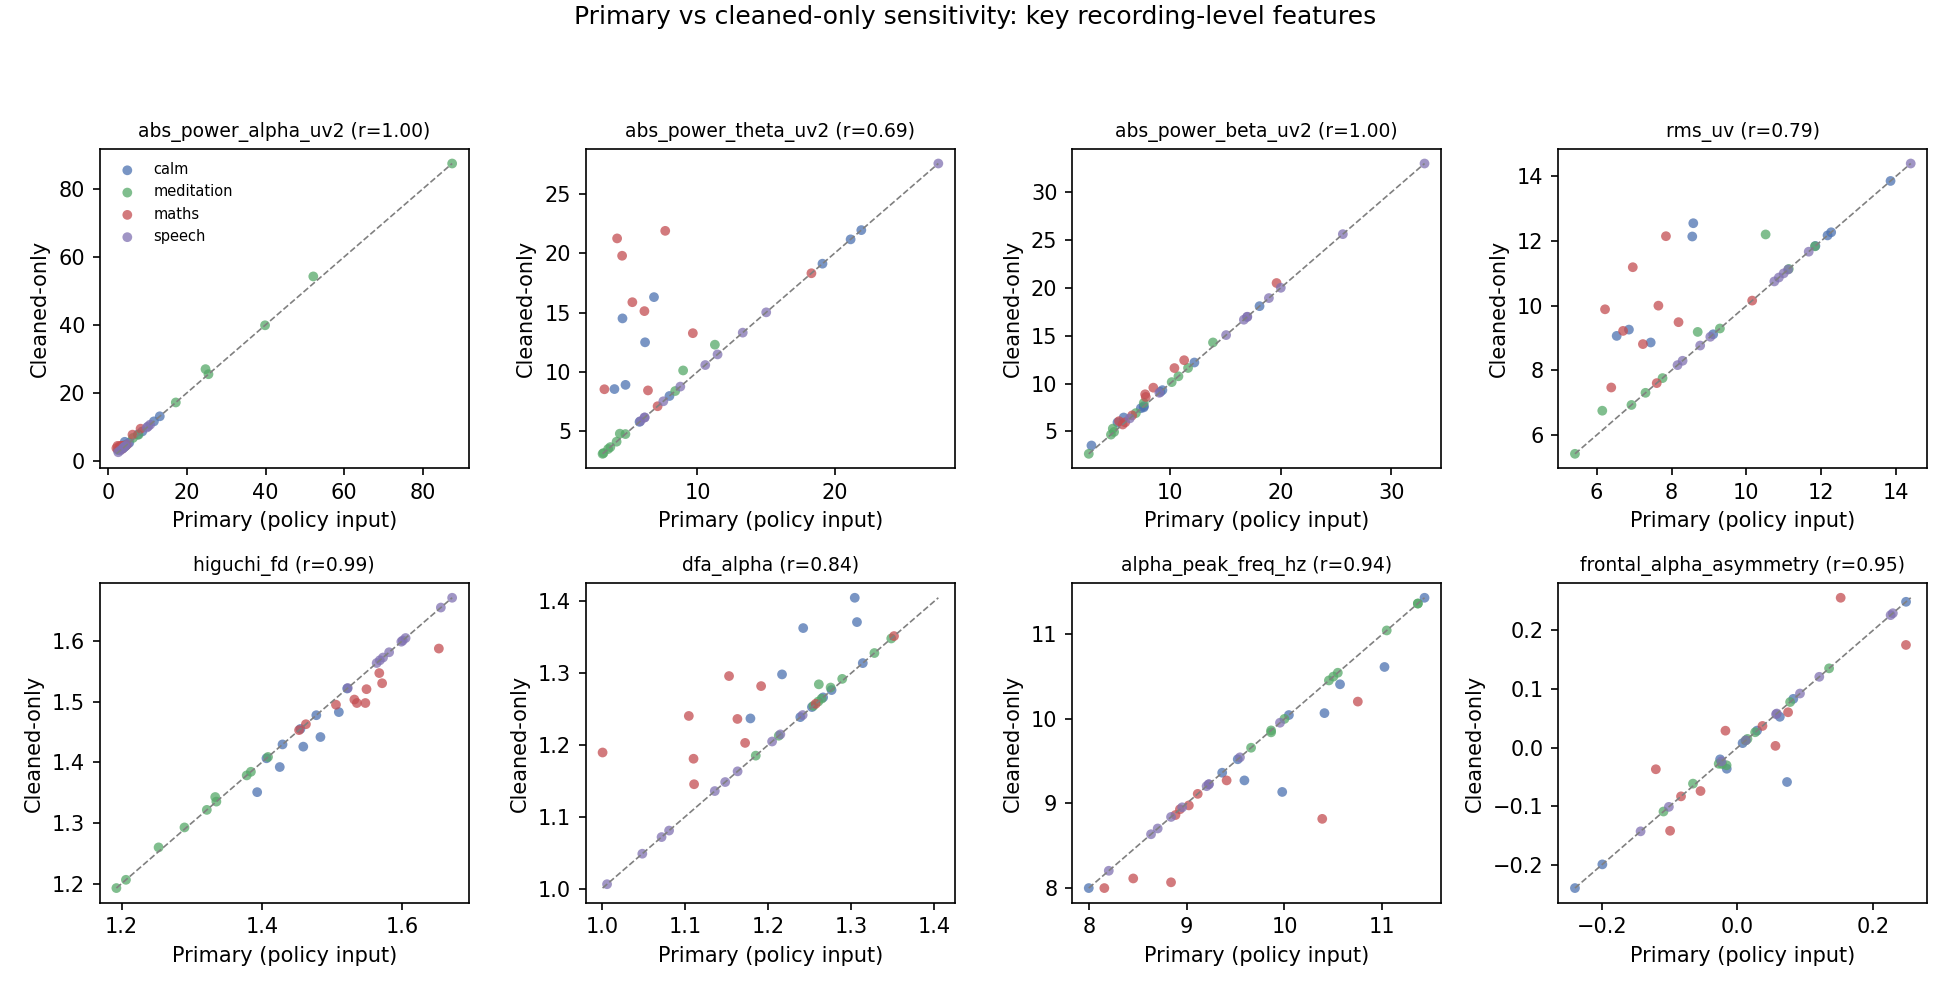

fig02_alpha_condition_means.png


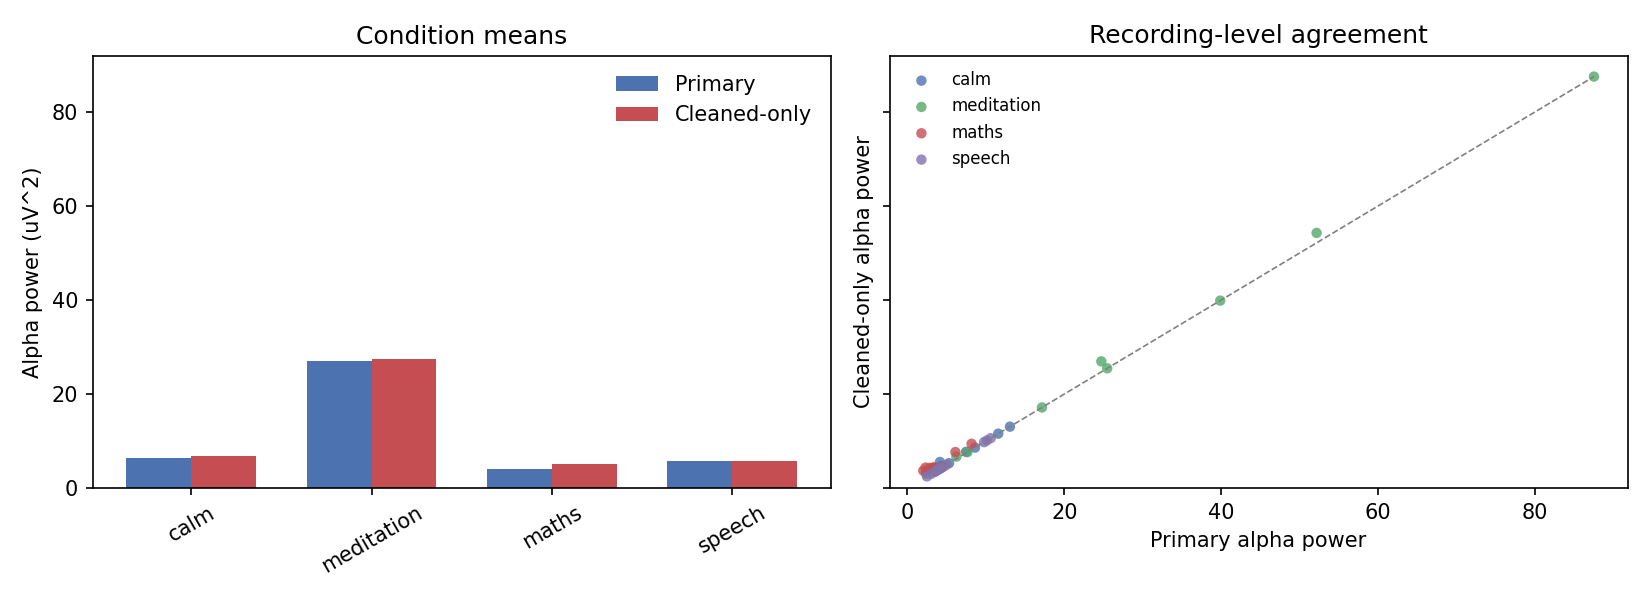

In [15]:
for p in sorted((sens_dir / "figures").glob("*.png")):
    print(p.name)
    display(Image(filename=str(p)))

In [16]:
display(Markdown((OUT / "validation_v1" / "VALIDATION_REPORT.md").read_text(encoding="utf-8")))

# EEG Feature Extraction - Validation Report (v1)

**Generated:** 2026-11-02T07:56:12Z
**Scope:** read-only validation of `EEG features/` v1 plus the cleaned-only sensitivity pass.

## Result

- Checks: **17**
- Status counts: **{'PASS': 16, 'WARN': 1}**

## Checks

| ID | Category | Check | Status | Value |
|---|---|---|---|---|
| V01 | structure | Output row counts | PASS | channel=960, recording=40, participant=10 |
| V02 | structure | 24 channels per recording; 10 per condition | PASS | channels=[np.int64(24)]; {'calm': 10, 'maths': 10, 'meditation': 10, 'speech': 10} |
| V03 | structure | No duplicate keys | PASS | 0 |
| V04 | values | No NaN/inf in channel features | PASS | 0 |
| V05 | values | Relative band powers sum to 1 | PASS | max |dev|=6.66e-16 |
| V06 | rules | Feature-input policy | PASS | 16 ICA / 24 cleaned; rejected ICA used=0 |
| V07 | rules | 931 artifact windows; no epoch overlaps an artifact | PASS | windows=931, overlapping epoch starts=0 |
| V08 | rules | M1/M2 non-scalp; 22 scalp channels aggregated | PASS | non_scalp=['M1', 'M2'], recordings_with_22=40/40 |
| V09 | rules | No labels or reference-sensitive features | PASS | [] |
| V10 | integrity | Input SHA-256 unchanged since extraction | PASS | 0 mismatches |
| V11 | independent | Spectral recomputation from saved PSD (trapezoid) | PASS | max relative diff=1.16e-07 |
| V11b | independent | Integration-rule sensitivity (rectangle vs trapezoid) | WARN | max relative diff=68.0% |
| V12 | independent | Independent temporal RMS recomputation | PASS | max relative diff=0.00e+00 |
| V13 | independent | Nonlinear kernel synthetic tests | PASS | HFD white=1.99, sine=1.08; DFA white=0.54, 1/f=1.43; PE white=0.99, const=0.00; LZ random>const=True |
| V14 | qc | Primary QC report has no FAIL | PASS | 0 FAIL |
| V15 | log | Extraction log 40/40 OK | PASS | 40 rows, status={'OK': 40} |
| V16 | structure | 10 participants with 4 recordings each | PASS | rows=10, n_recordings=[np.int64(4)] |

## Independent checks

- **V11** recomputes band power from the saved mean PSD with the same trapezoid rule,
  validating the table-to-PSD mapping. **V11b** reports what happens if rectangle
  integration is used instead; the difference is expected at low frequencies because
  the 1/f PSD is steep and the bands have few bins, so V11b is a warning, not a failure.
- **V12** recomputes RMS directly from the raw `.fif` epochs with `scipy.signal.detrend`,
  outside the library's epoch builder.
- **V13** runs the nonlinear kernels on synthetic signals with known expected values
  (white noise HFD ~2, sine HFD ~1, white-noise DFA ~0.5, 1/f DFA ~1.5).
- **V07** checks every saved epoch start against the artifact register; no valid epoch
  may overlap a registered artifact window.
- **V10** re-hashes every input file and compares it with the hash recorded at extraction.

## Sensitivity

The cleaned-only sensitivity tables and comparison are in
`validation_v1/sensitivity_cleaned_only/`.  See `sensitivity_summary.md` for the
feature-level agreement and key condition contrasts.

### Concrete sensitivity findings

- 118 of 151 numeric recording-level features have Pearson r >= 0.80;
  31 are moderate (0.50-0.80) and 0 are below 0.50.
- Alpha power is highly stable (r=0.999) and the meditation-vs-maths/calm alpha
  difference survives the input change. Beta power, Higuchi FD and alpha peak
  frequency are also stable (r >= 0.94).
- Theta power, delta power and RMS are sensitive to the ICA/cleaned choice.
  The RMS meditation-vs-maths contrast changes sign; the theta contrast keeps its
  direction but changes magnitude substantially.
- Frontal alpha asymmetry is stable across recordings (r=0.952), but its
  meditation-calm contrast is ~0.0002 and should not be interpreted.

| Feature | Pearson r | Interpretation |
|---|---:|---|
| abs_power_theta_uv2_mean | 0.687 | sensitivity-dependent |
| rms_uv_mean | 0.788 | sensitivity-dependent |
| dfa_alpha_mean | 0.844 | acceptable |
| alpha_peak_freq_hz_mean | 0.944 | stable |
| frontal_alpha_asymmetry | 0.952 | stable |
| higuchi_fd_mean | 0.988 | stable |
| abs_power_beta_uv2_mean | 0.998 | stable |
| abs_power_alpha_uv2_mean | 0.999 | stable |

- Key condition contrasts with a sign flip: **2** (rms_uv_mean, dfa_alpha_mean).
  The RMS flip is meaningful; the DFA flip is a near-zero meditation-calm difference.
- Recommendation: keep the policy-compliant primary table; report the cleaned-only
  table alongside theta, delta, RMS and any feature with r < 0.80. Do not claim a
  condition effect for a feature whose contrast sign flips.

## What this does and does not prove

- It proves the saved tables are structurally consistent, rule-compliant, reproducible
  from the saved inputs, and free of artifact-window leakage.
- It does **not** prove the features are clinically valid, reference-independent, or
  suitable for Dosha classification.  n = 10 and the provisional labels remain the
  binding limitations.


## 7. Next steps

1. Use the cleaned-only sensitivity table when interpreting theta, delta, RMS or
   any feature with r < 0.80; alpha/beta/HFD/alpha-peak conclusions are stable.
2. Join provisional labels (`Questionnaire_Analysis/participant_labels_v1.csv`) and
   speech features (`analysis_ready/participant_master_v1.csv`) on `participant_id`,
   keeping the provisional flag.
3. Confirm the acquisition reference (QC-01) before adding reference-sensitive
   features or connectivity.
4. Decide the interpolation policy for the 110 flagged channels (QC-04).
5. Only after labels are validated: feature selection and modelling with
   participant-level cross-validation.  n = 10 is exploratory.